Figure 3: bore speeds and energetics

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Run with current directory as the working directory. Make sure djl_stats.npz and bore_stats.npz are in this directory.
data_dir = Path('.')
djl_file = data_dir / 'djl_stats.npz'

def load_stats(path, keys, expected_shape=None):
    with np.load(path, allow_pickle=False) as data:
        stats = {key: data[key] for key in keys}
    shape = next(iter(stats.values())).shape
    if len(shape) != 2 or any(value.shape != shape for value in stats.values()):
        raise ValueError(f'{path}: expected matching mooring x bore arrays')
    if expected_shape is not None and shape != expected_shape:
        raise ValueError(f'{path}: expected shape {expected_shape}, got {shape}')
    return stats

bore = load_stats(data_dir / 'bore_stats.npz',
                  ('H', 'A', 'S', 'U', 'etaB', 'etaGC', 'max_depression', 'APE', 'KE'))
djl = load_stats(djl_file, ('c0', 'alpha', 'cDJL', 'etaDJL', 'max_gradient'),
                 expected_shape=bore['H'].shape)
print(f"Loaded mooring x bore grid: {bore['H'].shape}")

# The combined archive may be a checkpoint from a still-running batch job.
with np.load(djl_file, allow_pickle=False) as data:
    if 'processed' in data:
        pending = np.isfinite(bore['H']) & ~data['processed']
        if np.any(pending):
            print(f'WARNING: {np.count_nonzero(pending)} saved bore arrivals have not been processed; '
                  'figure counts may be incomplete.')


Loaded mooring x bore grid: (42, 164)


Classification and counts

In [2]:
H = bore['H']
S = bore['S']
U_B = bore['U']
c0 = djl['c0']
cDJL = djl['cDJL'].copy()
etaDJL = djl['etaDJL'] / H  
eta_observed = bore['max_depression'] / H

Delta_GC = np.full(H.shape, np.nan)
valid_index = np.isfinite(bore['etaB']) & np.isfinite(bore['etaGC']) & np.isfinite(S)
positive = valid_index & (bore['etaB'] > 0) & (S > 0)
Delta_GC[positive] = ((bore['etaGC'][positive] / bore['etaB'][positive])**2
                      * (1-S[positive]) / S[positive])
Delta_GC[valid_index & ~positive] = 0.0

deltastar = 0.1
condition0 = np.isfinite(H) & (U_B > 0.0*c0)
has_djl = cDJL > -1  
print('# mode-1 onshore propagating:', np.count_nonzero(condition0))
print('# existing DJL solutions:', np.count_nonzero(has_djl))

missing_djl_gc = condition0 & ~has_djl & (Delta_GC > deltastar)
print('# GCs without DJL solutions (use c0):', np.count_nonzero(missing_djl_gc))
cDJL[missing_djl_gc] = c0[missing_djl_gc]
etaDJL[missing_djl_gc] = 0.0

# 75% amplitude criterions
test_cond = ((0.75*etaDJL < eta_observed))
condition = condition0 & ((cDJL > -1) | (Delta_GC > deltastar))
condition2 = condition & (Delta_GC > deltastar)       # GCs
condition3 = condition & ~condition2 & test_cond      # ASIBs
condition4 = condition & ~condition2 & ~test_cond     # UIBs
unclassified = condition0 & ~condition

print('# DJL solution exists or GC index > 0.1:', np.count_nonzero(condition))
print('# GCs:', np.count_nonzero(condition2))
print('# ASIBs:', np.count_nonzero(condition3))
print('# UIBs:', np.count_nonzero(condition4))
print('# unclassified:', np.count_nonzero(unclassified))
print('# ASIBs + GCs:', np.count_nonzero(condition3 | condition2))
assert np.count_nonzero(condition2 | condition3 | condition4 | unclassified) == np.count_nonzero(condition0)


# mode-1 onshore propagating: 1762
# existing DJL solutions: 1614
# GCs without DJL solutions (use c0): 54
# DJL solution exists or GC index > 0.1: 1640
# GCs: 199
# ASIBs: 1234
# UIBs: 207
# unclassified: 122
# ASIBs + GCs: 1433


In [3]:
ASIB = condition3.copy()
UIB = condition4.copy()
GC = condition2.copy()
condition = ASIB | GC
condition1 = condition & (U_B < 0.5*c0)  
speed_good = condition & (U_B > 0.5*c0)
speed_equal = condition & (U_B == 0.5*c0)  
positive_speed = np.isfinite(cDJL) & (cDJL > 0) & np.isfinite(U_B) & (U_B > 0)
condition1 &= positive_speed
speed_good &= positive_speed
ratio = np.full(H.shape, np.nan)
np.divide(U_B, cDJL, out=ratio, where=positive_speed)

print('# ASIBs + GCs:', np.count_nonzero(condition))
print('# U_B < 0.5 c0 (grey):', np.count_nonzero(condition1))
print('# U_B > 0.5 c0 (colour):', np.count_nonzero(speed_good))
print('# U_B == 0.5 c0 (omitted):', np.count_nonzero(speed_equal))

for name, mask in [('ASIB', ASIB), ('GC', GC)]:
    r = ratio[mask & np.isfinite(ratio)]
    energy = (bore['KE'] + bore['APE'])[mask]
    energy = energy[np.isfinite(energy)]
    if len(r):
        print(f'{name}: N_speed={len(r)}, U_B/cDJL mean={np.mean(r):.3f}, median={np.median(r):.3f}')
    if len(energy):
        print(f'{name}: N_energy={len(energy)}, KE+APE mean={np.mean(energy):.3f}, median={np.median(energy):.3f}')

# Manually selected case-study indices; show only eligible ASIBs/GCs.
spydell = np.zeros(H.shape, dtype=bool)
for index in [(23, 70), (32, 77), (35, 83), (39, 71)]:
    spydell[index] = True
haney = np.zeros(H.shape, dtype=bool)
for index in [(0,19), (1,16), (2,16)]:
    haney[index] = True
spydell &= condition
haney &= condition
print('# highlighted Spydell/Haney arrivals:', np.count_nonzero(spydell), np.count_nonzero(haney))

# GC estimate: F*sqrt(gprime*H)/sqrt(S); A stores gprime.
# Constant F=0.5 (from Benjamin) for the inset
h_gc_fraction = np.full(H.shape, np.nan)
np.divide(bore['etaGC'], H, out=h_gc_fraction, where=np.isfinite(H) & (H > 0))
F = np.full(H.shape, np.nan)
valid_thickness = np.isfinite(h_gc_fraction) & (h_gc_fraction >= 0) & (h_gc_fraction <= 1)
F[valid_thickness] = 0.5
U_GC_est = np.full(H.shape, np.nan)
valid_estimate = (np.isfinite(bore['A']) & (bore['A'] > 0)
                  & np.isfinite(H) & (H > 0) & np.isfinite(S) & (S > 0)
                  & np.isfinite(F) & (F > 0))
U_GC_est[valid_estimate] = F[valid_estimate]*np.sqrt(bore['A'][valid_estimate]*H[valid_estimate])/np.sqrt(S[valid_estimate])
inset_mask = speed_good & GC & valid_estimate
measured_gc = U_B[inset_mask]
estimated_gc = U_GC_est[inset_mask]
if measured_gc.size:
    print(f'GC measured/estimated comparison (inset): N={measured_gc.size}')
    djl_reference_ratio = cDJL[inset_mask] / (0.5*np.sqrt(bore['A'][inset_mask]*H[inset_mask]))
    print(f'c_DJL / (0.5 sqrt(gprime H)): mean={np.mean(djl_reference_ratio):.4f}, '
          f'median={np.median(djl_reference_ratio):.4f}')
    print(f'Measured U_B [m/s]: mean={np.mean(measured_gc):.4f}, median={np.median(measured_gc):.4f}')
    print(f'Estimated U_GC [m/s]: mean={np.mean(estimated_gc):.4f}, median={np.median(estimated_gc):.4f}')
    print(f'U_B / U_GC_est: mean={np.mean(measured_gc/estimated_gc):.4f}, '
          f'median={np.median(measured_gc/estimated_gc):.4f}')
else:
    print('No eligible GCs for measured/estimated velocity statistics.')


# ASIBs + GCs: 1433
# U_B < 0.5 c0 (grey): 113
# U_B > 0.5 c0 (colour): 1320
# U_B == 0.5 c0 (omitted): 0
ASIB: N_speed=1234, U_B/cDJL mean=0.944, median=0.881
ASIB: N_energy=1234, KE+APE mean=0.057, median=0.046
GC: N_speed=199, U_B/cDJL mean=1.492, median=1.389
GC: N_energy=199, KE+APE mean=0.115, median=0.089
# highlighted Spydell/Haney arrivals: 4 2
GC measured/estimated comparison (inset): N=188
c_DJL / (0.5 sqrt(gprime H)): mean=0.7161, median=0.7152
Measured U_B [m/s]: mean=0.1775, median=0.1540
Estimated U_GC [m/s]: mean=0.1843, median=0.1731
U_B / U_GC_est: mean=0.9841, median=0.9026


In [4]:
depth_bin_edges = np.array([0, 15, 30, 45, 60, 103])
depth_labels = ['9–15m', '15–30m', '30–45m', '45–60m', '100m']
depth_masks = [speed_good & (H >= lo) & (H < hi)
               for lo, hi in zip(depth_bin_edges[:-1], depth_bin_edges[1:])]
data_to_plot = [ratio[mask] for mask in depth_masks] + [ratio[condition1]]
hist_bins = np.logspace(np.log10(0.1), np.log10(10), 25)
print('# coloured arrivals outside original depth bins:',
      np.count_nonzero(speed_good) - sum(np.count_nonzero(m) for m in depth_masks))
print('# plotted-population ratios outside histogram range:',
      np.count_nonzero((speed_good | condition1) & ((ratio < hist_bins[0]) | (ratio > hist_bins[-1]))))


# coloured arrivals outside original depth bins: 0
# plotted-population ratios outside histogram range: 9


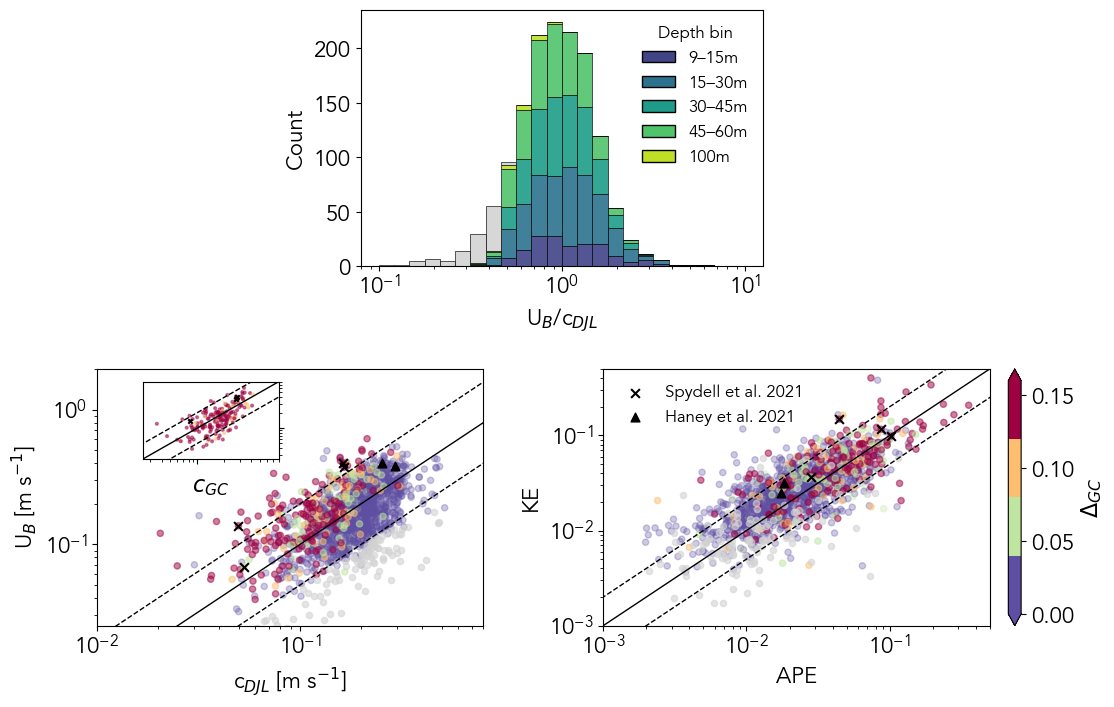

In [5]:
plt.rcParams.update({
    'axes.facecolor': 'white', 'axes.grid': False,
    'font.family': 'sans-serif', 'font.sans-serif': ['Avenir', 'Avenir Next', 'Arial', 'DejaVu Sans'],
    'font.size': 16, 'text.usetex': False,
})
spectral_discrete = plt.get_cmap('Spectral_r', 4)
fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(2, 4, hspace=0.4, wspace=0.9)
ax_a = fig.add_subplot(gs[0, 1:3])
ax_b = fig.add_subplot(gs[1, 0:2])
ax_c = fig.add_subplot(gs[1, 2:4])
ax_inset = ax_b.inset_axes([0.12, 0.65, 0.35, 0.3])

# (a) Depth colours underneath the low-speed grey group.
depth_colors = list(plt.cm.viridis(np.linspace(0.2, 0.9, len(depth_labels))))
ax_a.hist(data_to_plot, bins=hist_bins, stacked=True,
          color=depth_colors + ['lightgrey'], edgecolor='black', linewidth=0.5, alpha=0.9)
ax_a.set_xscale('log')
ax_a.set_xlabel(r'U$_B$/c$_{DJL}$')
ax_a.set_ylabel('Count')
handles = [plt.Rectangle((0, 0), 1, 1, color=color, ec='black') for color in depth_colors]
ax_a.legend(handles, depth_labels, title='Depth bin', title_fontsize=12,
            fontsize=12, frameon=False, loc='upper right')

# Alpha split at Delta_GC=0.05; GC classification itself is at 0.1.
def coloured_scatter(ax, xx, yy):
    valid = speed_good & np.isfinite(xx) & np.isfinite(yy) & (xx > 0) & (yy > 0)
    for mask, opacity in [(valid & (Delta_GC < 0.05), 0.3),
                          (valid & (Delta_GC > 0.05), 0.5)]:
        ax.scatter(xx[mask], yy[mask], c=Delta_GC[mask], vmin=0, vmax=0.16,
                   cmap=spectral_discrete, alpha=opacity, s=20)
    grey = condition1 & np.isfinite(xx) & np.isfinite(yy) & (xx > 0) & (yy > 0)
    ax.scatter(xx[grey], yy[grey], c='lightgrey', alpha=0.6, s=20)

# (b) Speeds; GC inset compares measured speed with 0.5*sqrt(gprime*H/S).
coloured_scatter(ax_b, cDJL, U_B)
inset_mask = speed_good & GC & valid_estimate
ax_inset.scatter(U_GC_est[inset_mask], U_B[inset_mask],
                 c=Delta_GC[inset_mask], vmin=0, vmax=0.16,
                 cmap=spectral_discrete, alpha=0.5, s=4)
case_inset = spydell & GC & positive_speed & valid_estimate
ax_inset.scatter(U_GC_est[case_inset], U_B[case_inset],
                 c='black', s=10, marker='x')

APE, KE = bore['APE'], bore['KE']
coloured_scatter(ax_c, APE, KE)
for mask, marker, label in [(spydell, 'x', 'Spydell et al. 2021'),
                            (haney, '^', 'Haney et al. 2021')]:
    speed_mask = mask & positive_speed
    ax_b.scatter(cDJL[speed_mask], U_B[speed_mask], c='black', s=40, marker=marker)
    energy_mask = mask & np.isfinite(APE) & np.isfinite(KE) & (APE > 0) & (KE > 0)
    ax_c.scatter(APE[energy_mask], KE[energy_mask], c='black', s=40, marker=marker, label=label)
ax_c.legend(fontsize=12, frameon=False, loc='upper left')

# 1:1, 2:1 and 1:2 reference lines and axis ranges.
for ax, limits in [(ax_b, (0.01, 2)), (ax_inset, (0.01, 2)), (ax_c, (1e-4, 1))]:
    reference = np.geomspace(*limits, 100)
    ax.plot(reference, reference, 'k-', lw=1)
    ax.plot(reference, 2*reference, 'k--', lw=1)
    ax.plot(reference, 0.5*reference, 'k--', lw=1)
    ax.set_xscale('log')
    ax.set_yscale('log')
ax_b.set(xlim=(0.01, 0.8), ylim=(0.025, 2),
         xlabel=r'c$_{DJL}$ [m s$^{-1}$]', ylabel=r'U$_B$ [m s$^{-1}$]')
ax_inset.set(xlim=(0.025, 0.8), ylim=(0.025, 0.8),
             xlabel=r'$c_{GC}$')
ax_inset.yaxis.tick_right()
ax_inset.set_xticklabels([])
ax_inset.set_yticklabels([])
ax_inset.tick_params(axis='both', which='major', labelsize=10)
ax_c.set(xlim=(1e-3, 0.5), ylim=(1e-3, 0.5), xlabel='APE', ylabel='KE')

mappable = plt.cm.ScalarMappable(norm=plt.Normalize(0, 0.16), cmap=spectral_discrete)
fig.colorbar(mappable, ax=[ax_b, ax_c], orientation='vertical', fraction=0.02,
             pad=0.02, extend='both', label=r'$\Delta_{GC}$')
# for ax, label in zip((ax_a, ax_b, ax_c), ('a)', 'b)', 'c)')):
#     ax.text(-0.08, 1.04, label, transform=ax.transAxes, fontsize=16, fontweight='bold')

fig.savefig(data_dir / 'fig3_noannotation.pdf', bbox_inches='tight', dpi=300)
fig.savefig(data_dir / 'fig3_noannotation.png', bbox_inches='tight', dpi=300)
plt.show()


In [6]:
# KE/APE statistics for the full classified groups (including the grey speed group).
valid_energy_ratio = (np.isfinite(bore['KE']) & np.isfinite(bore['APE'])
                      & (bore['APE'] > 0))
KE_APE = np.full(H.shape, np.nan)
np.divide(bore['KE'], bore['APE'], out=KE_APE, where=valid_energy_ratio)
for name, group in [('GCs', GC), ('ASIBs', ASIB), ('GCs + ASIBs', GC | ASIB)]:
    values = KE_APE[group & valid_energy_ratio]
    if values.size:
        print(f'{name}: N={values.size}, KE/APE mean={np.mean(values):.4f}, '
              f'median={np.median(values):.4f}')
    else:
        print(f'{name}: no valid KE/APE values')


GCs: N=199, KE/APE mean=1.4557, median=1.0584
ASIBs: N=1234, KE/APE mean=1.3896, median=1.1575
GCs + ASIBs: N=1433, KE/APE mean=1.3987, median=1.1507
